In [1]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 29.7 MB/s  0:00:03


# Task 06 — Ames Housing (Regression)
**Goal:** predict the sale price of a house. **Target:** `SalePrice` (we train on `log(SalePrice)` because prices are skewed). **Features:** 79 columns about size, quality, age, location, garage, basement...

**Metrics:** MAE, MSE, RMSE and R². Errors are reported on the log scale and in real dollars.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

## 1. Load the data

In [3]:
import os
path = 'dataset/Ames_Housing_Dataset.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'Ames_Housing_Dataset.csv'
df = pd.read_csv(path)

In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
df.shape

(1460, 81)

In [6]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [9]:
df["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


## 2. Data cleaning

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df.drop_duplicates()

In [12]:
df = df.drop(columns="Id")

In [13]:
df.isnull().sum().sort_values(ascending=False).head(20)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageType,81
GarageFinish,81


**Missing values:** in this dataset many `NA` mean *no such feature* (no alley, no pool, no garage...), so text columns become the category `None`. `GarageYrBlt` / `MasVnrArea` use fixed rules. `LotFrontage` needs a median, so it is filled **after the split** with the train median (before, the median of the whole data was used = leakage).

In [14]:
text_cols = df.select_dtypes(exclude="number").columns
df[text_cols] = df[text_cols].fillna("None")

In [15]:
# GarageYrBlt: no garage -> same year as the house; MasVnrArea: no veneer -> 0 (fixed rules, no leakage)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
# LotFrontage needs a median -> it is filled AFTER the split with the median of the train data (data leakage fix)

In [16]:
missing = df.isnull().sum()
print(missing[missing > 0])

LotFrontage    259
dtype: int64


## 3. EDA (visualization)

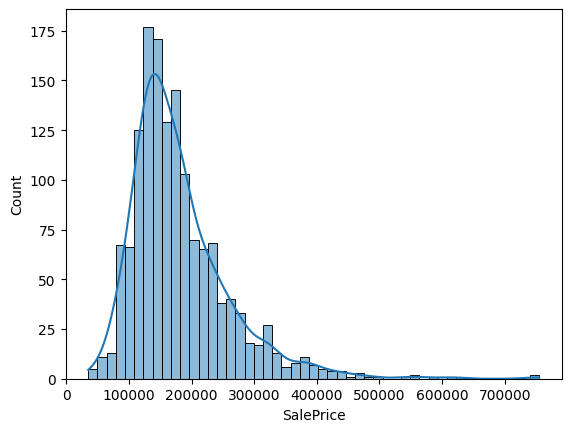

In [17]:
sns.histplot(df["SalePrice"], kde=True)
plt.show()

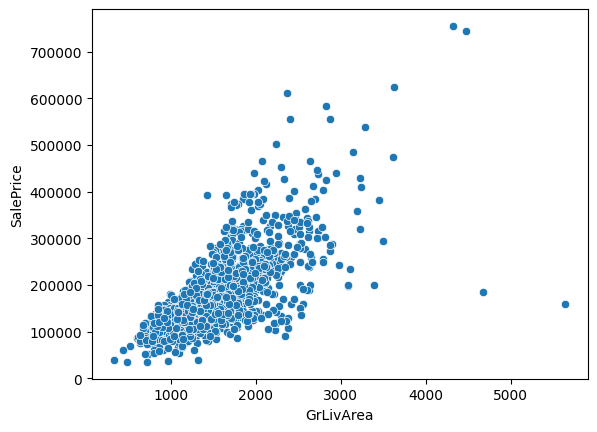

In [18]:
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)
plt.show()

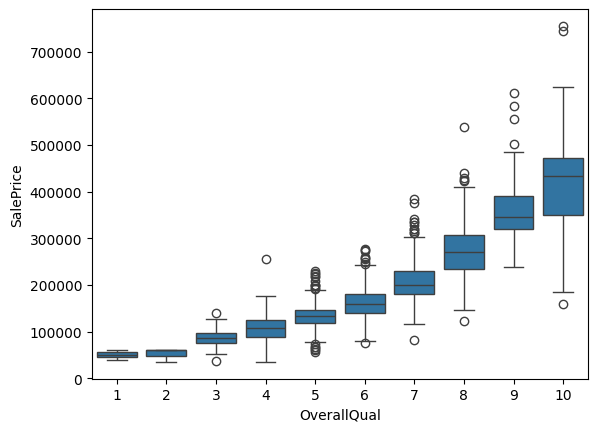

In [19]:
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.show()

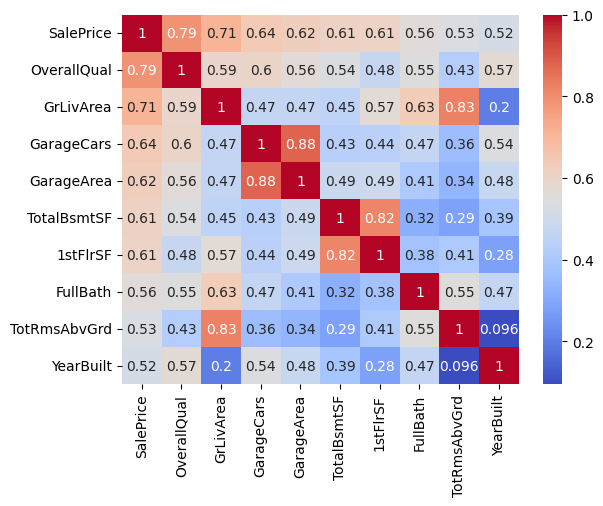

In [20]:
top_cols = df.corr(numeric_only=True)["SalePrice"].abs().sort_values(ascending=False).head(10).index
sns.heatmap(df[top_cols].corr(), annot=True, cmap="coolwarm")
plt.show()

### Outliers (IQR rule)

In [21]:
for col in ['SalePrice', 'GrLivArea', 'LotArea', 'TotalBsmtSF']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(df) * 100:.1f}%)  [valid range {low:.0f} to {high:.0f}]  max = {df[col].max():.0f}")
print("Houses with GrLivArea >= 4000:", (df['GrLivArea'] >= 4000).sum())

SalePrice: 61 outliers (4.2%)  [valid range 3938 to 340038]  max = 755000
GrLivArea: 31 outliers (2.1%)  [valid range 159 to 2748]  max = 5642
LotArea: 69 outliers (4.7%)  [valid range 1482 to 17674]  max = 215245
TotalBsmtSF: 61 outliers (4.2%)  [valid range 42 to 2052]  max = 6110
Houses with GrLivArea >= 4000: 4


**Decision:** most IQR outliers are real (big or luxury houses), so they are **kept**; the skew is handled with `log1p` (target and skewed features, below). The only rows removed are the houses with `GrLivArea >= 4000` (next cell): the scatter plot above shows that they are huge houses sold for a very low price (partial sales), which does not follow the pattern and is a known problem of this dataset.

In [22]:
df = df[df["GrLivArea"] < 4000]

In [23]:
df_clean = df.copy()

## 4. Encoding
Quality columns (Po/Fa/TA/Gd/Ex) become numbers 0-5, other categories are one-hot encoded, the 3 columns with many categories use target encoding (computed from the train data only, after the split).

In [24]:
quality = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
quality_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for col in quality_cols:
    df[col] = df[col].map(quality)

In [25]:
df["CentralAir"] = df["CentralAir"].map({"N": 0, "Y": 1})

In [26]:
df["MSSubClass"] = df["MSSubClass"].astype(str)

In [27]:
high_card = ["Neighborhood", "Exterior1st", "Exterior2nd"]

In [28]:
onehot_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in high_card]
df = pd.get_dummies(df, columns=onehot_cols, drop_first=True, dtype=int)

In [29]:
X = df.drop(columns="SalePrice")

In [30]:
y = np.log1p(df["SalePrice"])

## 5. Train / Test split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Fill missing `LotFrontage` (median of the train data only, then applied to test) -> no data leakage

In [32]:
lot_frontage_median = X_train["LotFrontage"].median()      # from the train data only
X_train = X_train.copy()
X_test = X_test.copy()
X_train["LotFrontage"] = X_train["LotFrontage"].fillna(lot_frontage_median)
X_test["LotFrontage"] = X_test["LotFrontage"].fillna(lot_frontage_median)

print("Missing values left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Missing values left: 0 0


In [33]:
target_means = {}
for col in high_card:
    target_means[col] = y_train.groupby(X_train[col]).mean()
    X_train[col] = X_train[col].map(target_means[col])
    X_test[col] = X_test[col].map(target_means[col]).fillna(y_train.mean())

## 6. Skewed features and scaling (fit on train only)

In [34]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]

In [35]:
skewed = [c for c in num_cols if abs(X_train[c].skew()) > 0.75]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed] = np.log1p(X_test[skewed])

In [36]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [37]:
y_real = np.expm1(y_test)

## 7. First models with GridSearchCV
A first look at 4 models (the grids are small). This part prints test errors in dollars; the final model is selected later with cross-validation on the training data only.

In [38]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN": GridSearchCV(KNeighborsRegressor(),
                        {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance']},
                        cv=5, scoring='r2'),
    "SVR": GridSearchCV(SVR(), {'C': [0.01, 0.1, 1], 'kernel': ['linear', 'rbf']},
                        cv=5, scoring='r2'),
    "Decision Tree": GridSearchCV(DecisionTreeRegressor(criterion="squared_error", random_state=100),
                                  {'max_depth': [5, 10, 15], 'min_samples_leaf': [1, 5, 10]},
                                  cv=5, scoring='r2'),
}

In [39]:
results = []

In [40]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = np.expm1(model.predict(X_test))

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_real, y_pred),
        'MSE': mean_squared_error(y_real, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'R2': r2_score(y_real, y_pred)
    })

for name, model in models.items():
    if hasattr(model, "best_params_"):
        print("Best Parameters", name, ":", model.best_params_)

results_df = pd.DataFrame(results).set_index('Model').sort_values('R2', ascending=False)
results_df.round(3)

Best Parameters KNN : {'n_neighbors': 9, 'weights': 'distance'}
Best Parameters SVR : {'C': 0.01, 'kernel': 'linear'}
Best Parameters Decision Tree : {'max_depth': 15, 'min_samples_leaf': 10}


,MAE,MSE,RMSE,R2
Model,,,,
SVR,13732.219,3.806011e+08,19509.000,0.927
Linear Regression,14207.955,4.203866e+08,20503.332,0.920
KNN,20499.064,9.599378e+08,30982.863,0.817
Decision Tree,22486.342,1.182343e+09,34385.211,0.775


In [41]:
best_model = models[results_df.index[0]]
print("Best Model:", results_df.index[0])

Best Model: SVR


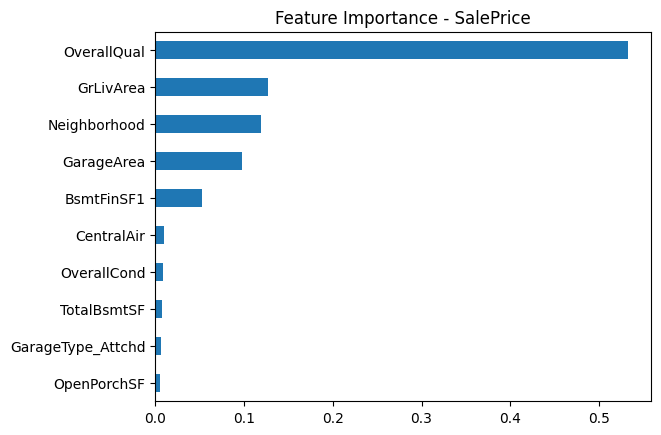

In [42]:
imp = pd.Series(models["Decision Tree"].best_estimator_.feature_importances_, index=X_train.columns)
imp.sort_values(ascending=False).head(10).sort_values().plot(kind="barh", title="Feature Importance - SalePrice")
plt.show()

## 8. All the models
All models of the track are trained on the log target and evaluated on the test set (errors on the log scale).

In [43]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [44]:
from sklearn.linear_model import ElasticNet
models["ElasticNet"] = ElasticNet()

In [45]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/16 [00:00<?, ?it/s]

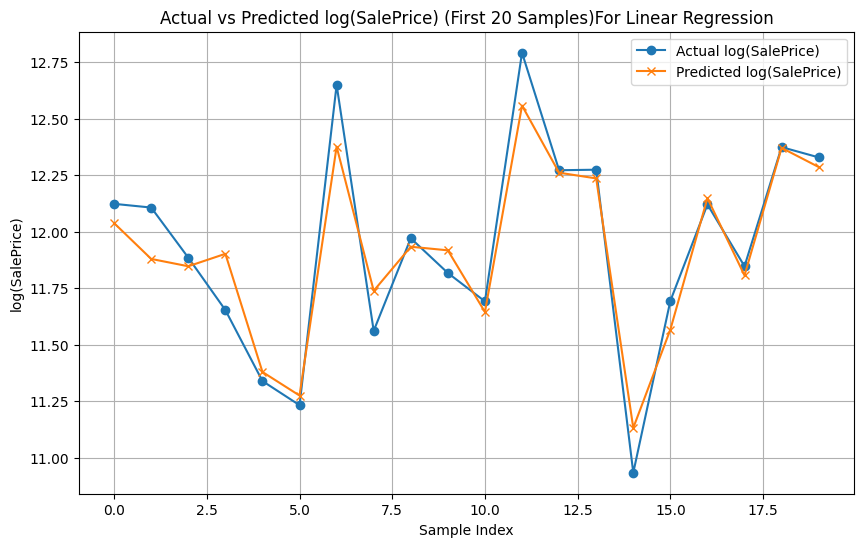

  6%|▋         | 1/16 [00:00<00:03,  3.81it/s]

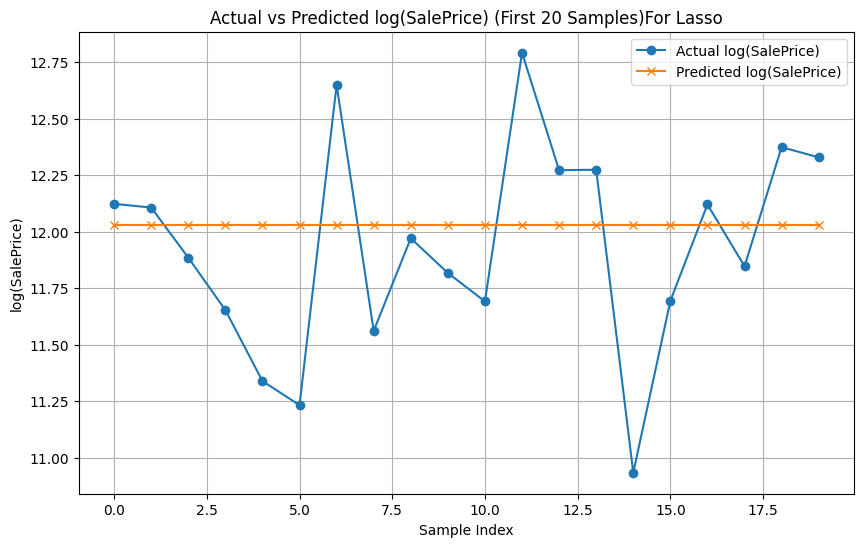

 12%|█▎        | 2/16 [00:00<00:03,  4.28it/s]

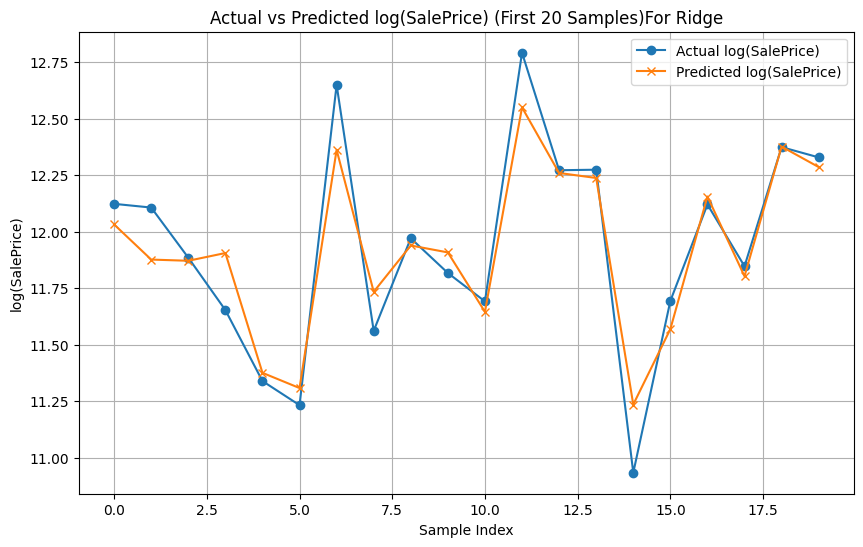

 19%|█▉        | 3/16 [00:00<00:03,  3.49it/s]

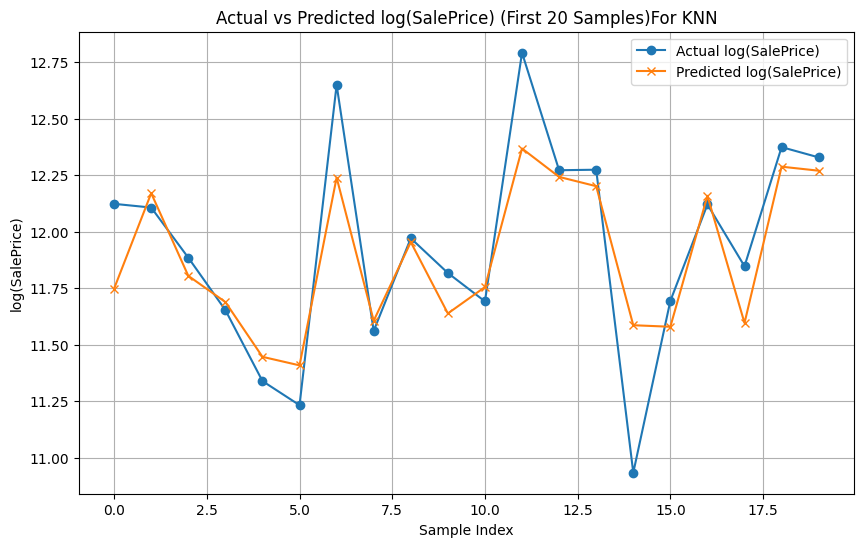

 25%|██▌       | 4/16 [00:01<00:05,  2.25it/s]

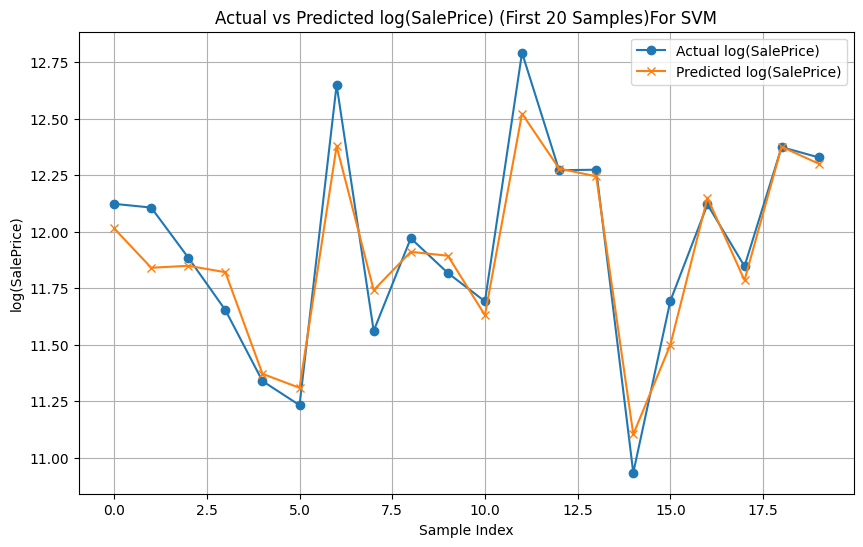

 31%|███▏      | 5/16 [00:04<00:16,  1.46s/it]

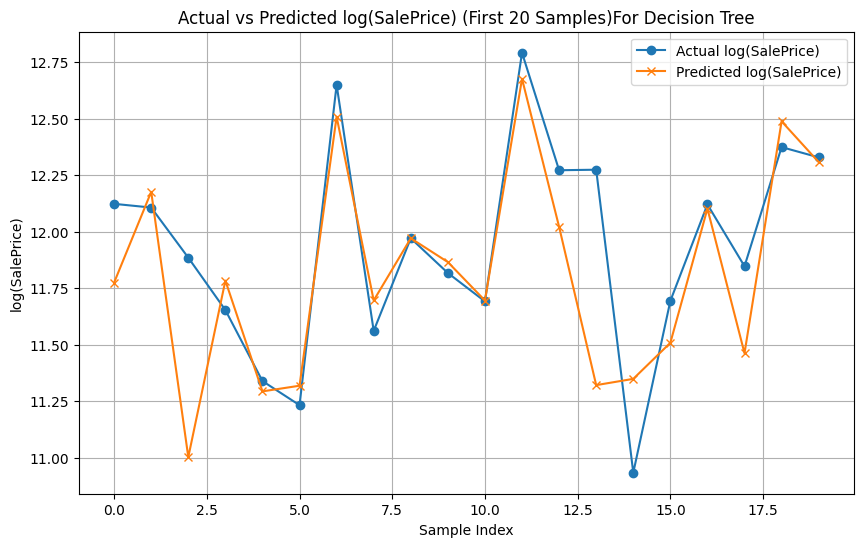

 38%|███▊      | 6/16 [00:05<00:11,  1.10s/it]

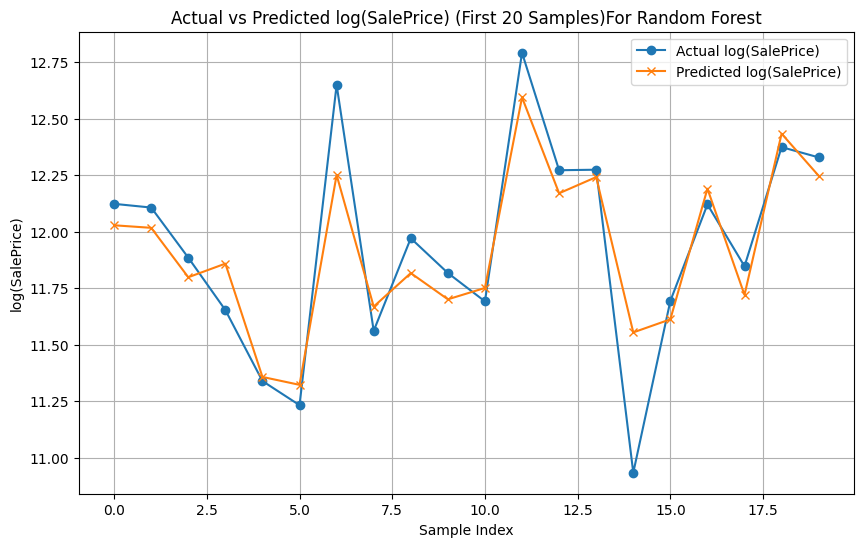

 44%|████▍     | 7/16 [00:06<00:11,  1.26s/it]

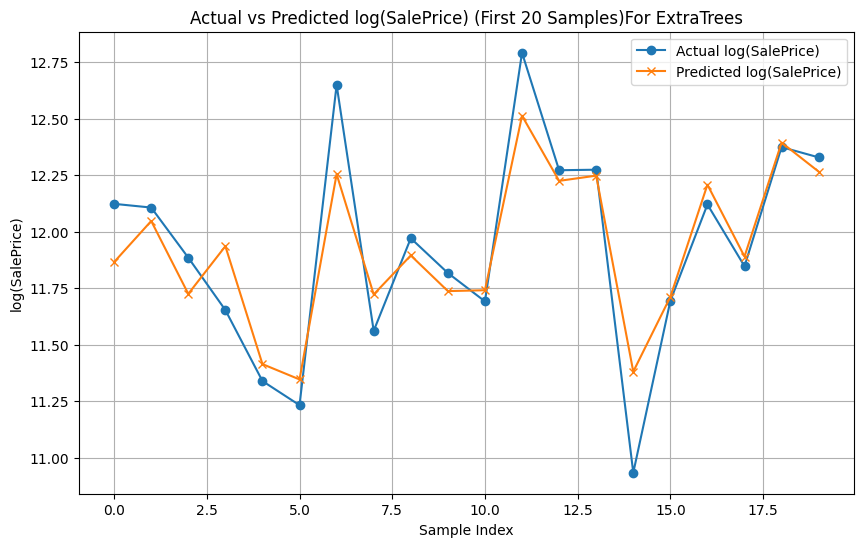

 50%|█████     | 8/16 [00:09<00:14,  1.85s/it]

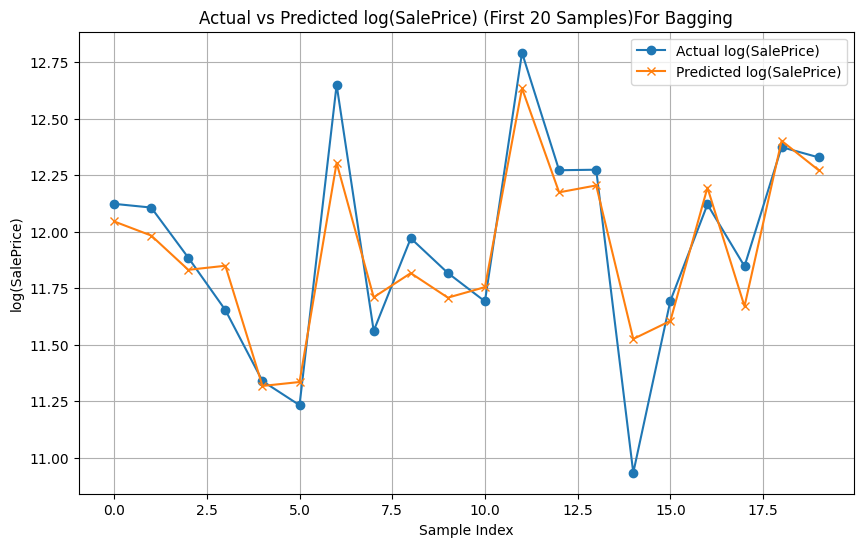

 56%|█████▋    | 9/16 [00:11<00:12,  1.78s/it]

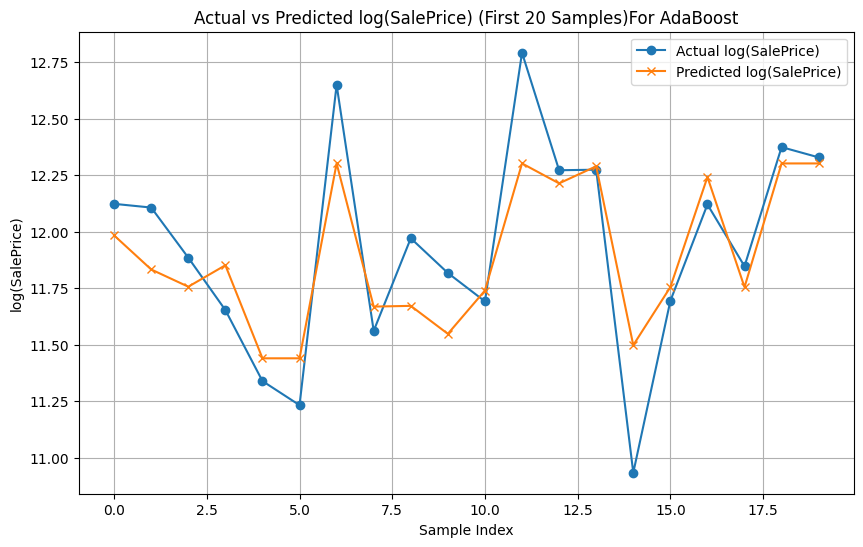

 62%|██████▎   | 10/16 [00:11<00:08,  1.36s/it]

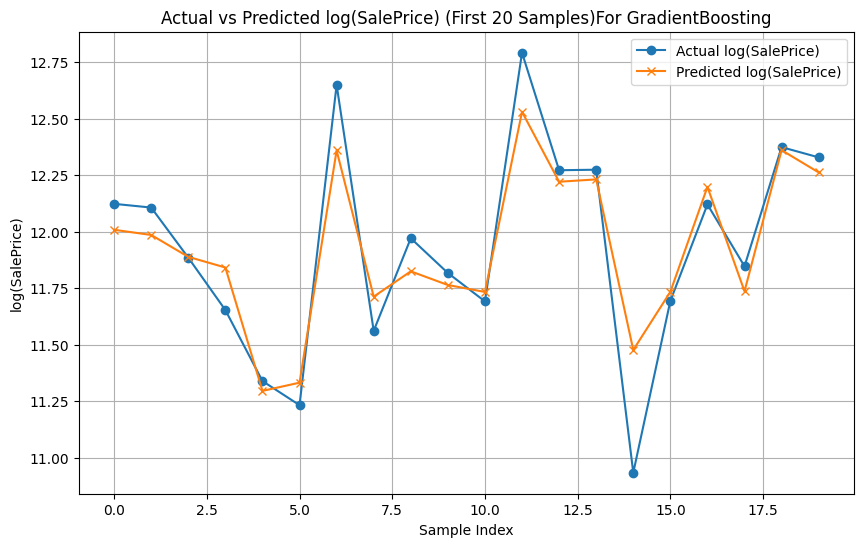

 69%|██████▉   | 11/16 [00:13<00:06,  1.32s/it]

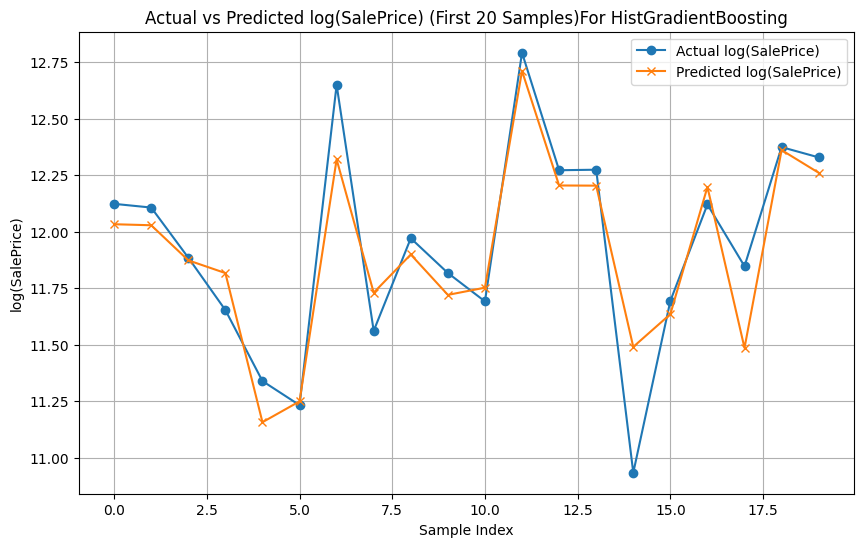

 75%|███████▌  | 12/16 [00:14<00:05,  1.33s/it]

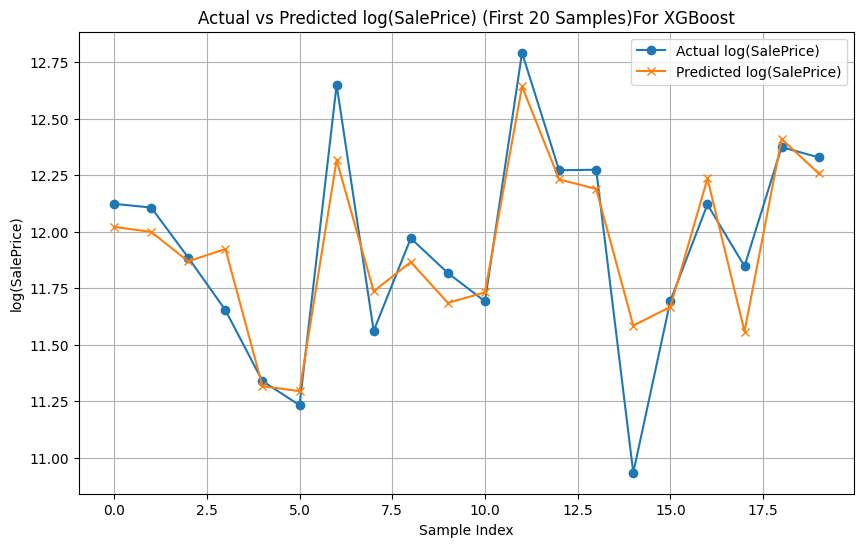

 81%|████████▏ | 13/16 [00:15<00:03,  1.19s/it]

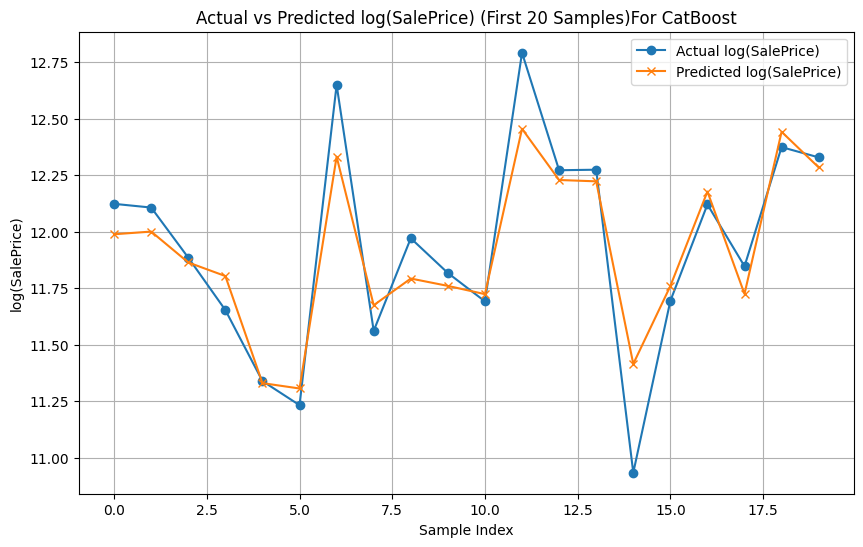

 88%|████████▊ | 14/16 [00:16<00:02,  1.27s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002728 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3164
[LightGBM] [Info] Number of data points in the train set: 1164, number of used features: 127
[LightGBM] [Info] Start training from score 12.028422


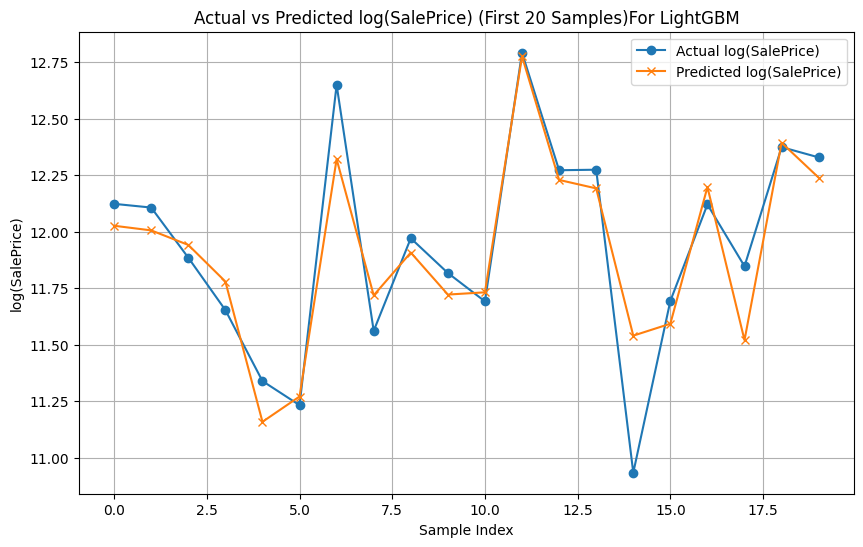

 94%|█████████▍| 15/16 [00:17<00:01,  1.10s/it]

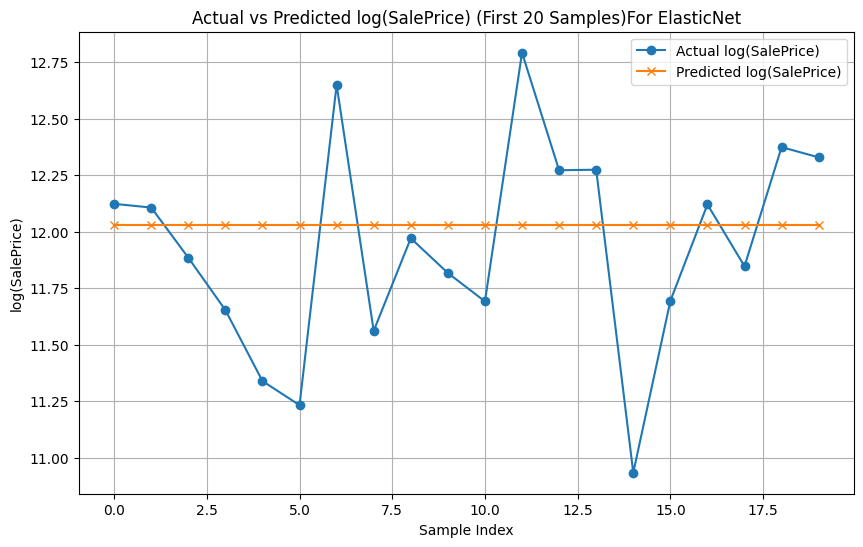

100%|██████████| 16/16 [00:17<00:00,  1.12s/it]


In [46]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual log(SalePrice)', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted log(SalePrice)', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('log(SalePrice)')
    plt.title('Actual vs Predicted log(SalePrice) (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [47]:
# Voting regressors (averaging). The old 'Simple Voting' was identical to 'Voting', so it is kept once.
def add_errors(name, model):
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model, X_test, y_test)
    errors[name] = {
        "MAE Train": MAE_Train, "MAE Test": MAE_Test,
        "MSE Train": MSE_Train, "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train, "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train, "R2 Test": R2_Test
    }

clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

model1 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)])
model3 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], weights=[2, 1, 2])

model1.fit(X_train, y_train)
model3.fit(X_train, y_train)

add_errors("Voting", model1)
add_errors("Weighted Voting", model3)

In [48]:
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=XGBRegressor(),
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_regressor.fit(X_train, y_train)
add_errors("Stacking", stacking_regressor)

In [49]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [50]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
CatBoost,6.164194e-02,0.081694,6.935517e-03,0.014069,8.327975e-02,0.118614,0.955618,0.910920
Ridge,6.844292e-02,0.083747,9.048486e-03,0.014280,9.512353e-02,0.119499,0.942096,0.909585
Linear Regression,6.716613e-02,0.085024,8.786831e-03,0.014427,9.373810e-02,0.120113,0.943771,0.908653
SVM,7.237467e-02,0.087225,9.551721e-03,0.015102,9.773291e-02,0.122892,0.938876,0.904378
GradientBoosting,5.586281e-02,0.087824,5.559063e-03,0.016053,7.455912e-02,0.126699,0.964426,0.898361
HistGradientBoosting,2.422758e-02,0.087914,1.449903e-03,0.016391,3.807759e-02,0.128028,0.990722,0.896217
LightGBM,2.417004e-02,0.088447,1.438188e-03,0.017251,3.792344e-02,0.131345,0.990797,0.890772
ExtraTrees,1.082448e-14,0.092015,1.755744e-28,0.018353,1.325045e-14,0.135473,1.000000,0.883798
Voting,3.081201e-02,0.094192,1.948028e-03,0.018406,4.413647e-02,0.135669,0.987534,0.883461
Weighted Voting,3.156863e-02,0.097344,2.000323e-03,0.019103,4.472497e-02,0.138215,0.987199,0.879045


<Axes: >

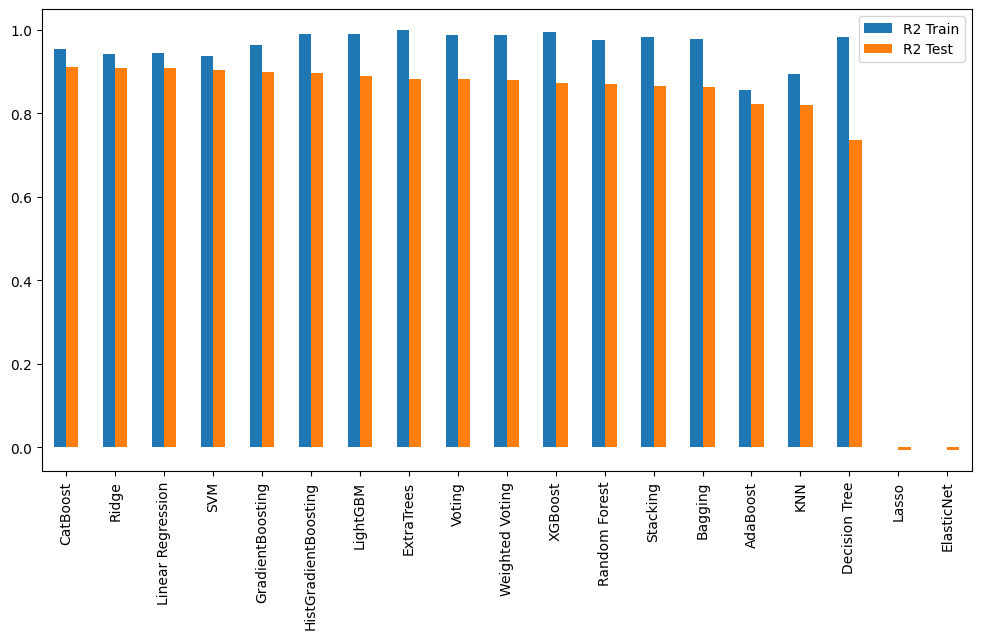

In [51]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

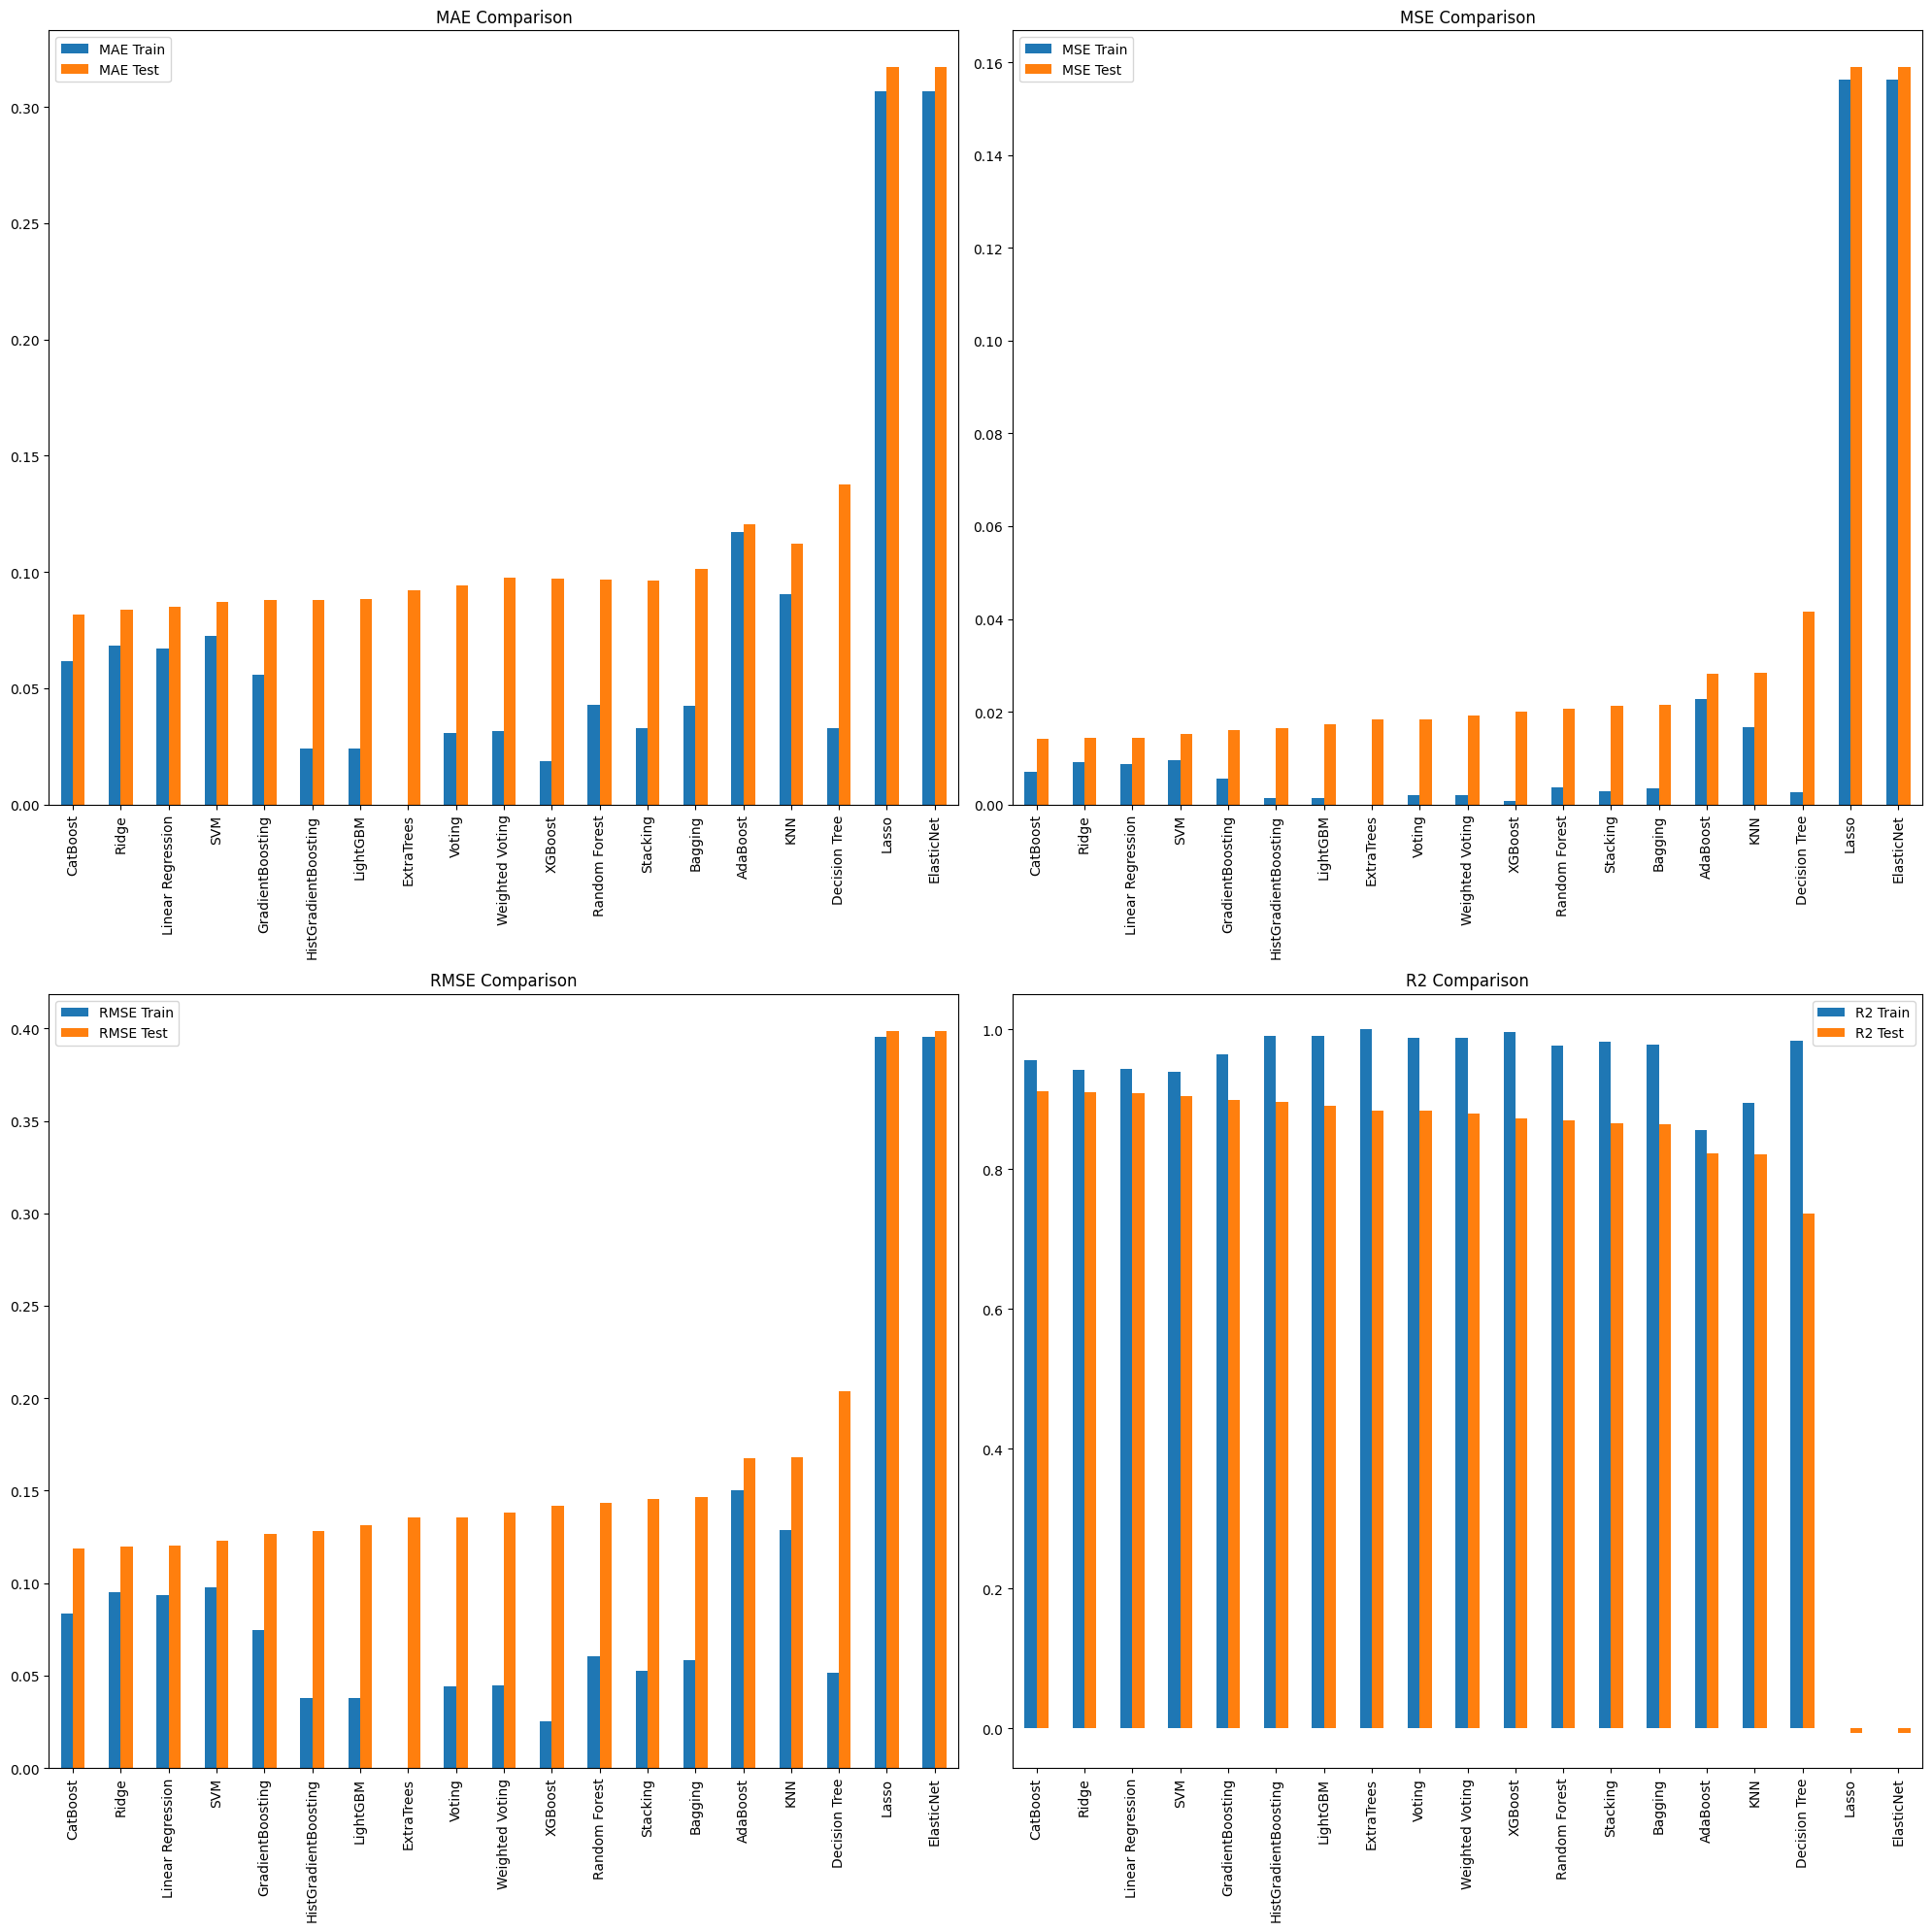

In [52]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** the table above uses the test set to show how each model behaves (errors are on the **log(SalePrice)** scale). To **choose** and **tune** the final model we do not use the test set: we use cross-validation on the training data (next sections). Large gaps between Train and Test R² mean overfitting (e.g. Decision Tree, ExtraTrees, Random Forest).

## 9. Model comparison with Cross-Validation (train data only)
5-fold cross-validation on the training data, metric **R²** (and RMSE on log(SalePrice)).

In [53]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, model in tqdm(models.items()):
    cv = cross_validate(clone(model), X_train, y_train, cv=kf, n_jobs=-1,
                        scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'})
    cv_rows[name] = {'CV R2': cv['test_r2'].mean(), 'CV RMSE (log)': -cv['test_rmse'].mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values('CV R2', ascending=False)
cv_df

100%|██████████| 16/16 [00:50<00:00,  3.17s/it]


,CV R2,CV RMSE (log)
Ridge,0.906152,0.120196
CatBoost,0.902247,0.122168
GradientBoosting,0.900857,0.122628
SVM,0.899439,0.123920
LightGBM,0.899320,0.124177
HistGradientBoosting,0.896359,0.125739
XGBoost,0.885055,0.132614
Linear Regression,0.881714,0.134183
ExtraTrees,0.881159,0.134835
Bagging,0.876569,0.137163


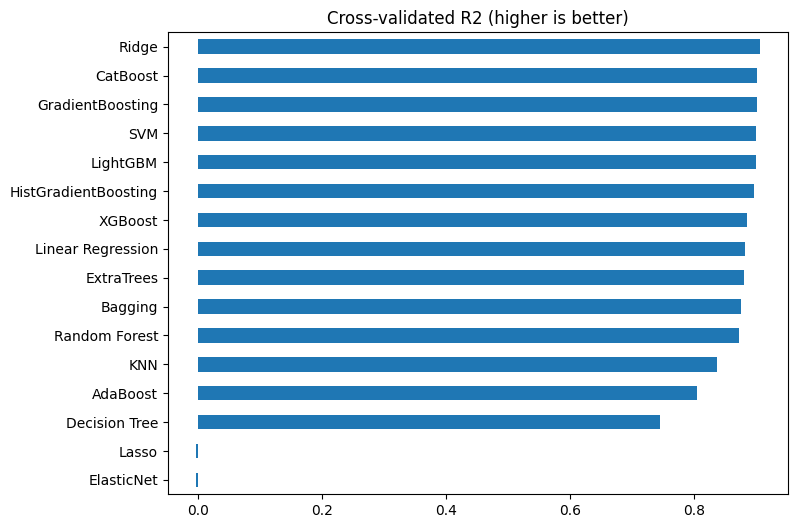

In [54]:
cv_df['CV R2'].sort_values().plot.barh(figsize=(8, 6))
plt.title('Cross-validated R2 (higher is better)')
plt.show()

## 10. GridSearchCV on the best 3 models
The top 3 models of the cross-validation comparison are tuned with `GridSearchCV` (5-fold, metric R², training data only).

In [55]:
param_grids = {
    'Linear Regression': {'fit_intercept': [True, False]},
    'Lasso': {'alpha': [0.0001, 0.0005, 0.001, 0.01]},
    'Ridge': {'alpha': [1, 3, 10, 30, 100]},
    'ElasticNet': {'alpha': [0.0005, 0.001, 0.01], 'l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'n_neighbors': [3, 5, 9, 15], 'weights': ['uniform', 'distance']},
    'SVM': {'C': [0.1, 1], 'epsilon': [0.01, 0.1]},
    'Decision Tree': {'max_depth': [4, 6, 10], 'min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'n_estimators': [100, 300], 'max_depth': [10, None], 'min_samples_leaf': [1, 3]},
    'ExtraTrees': {'n_estimators': [100, 300], 'max_depth': [10, None], 'min_samples_leaf': [1, 3]},
    'Bagging': {'n_estimators': [50, 100], 'max_samples': [0.7, 1.0]},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.05, 0.1, 0.5]},
    'GradientBoosting': {'n_estimators': [200, 500], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 3]},
    'HistGradientBoosting': {'max_iter': [200, 400], 'learning_rate': [0.03, 0.1], 'max_depth': [None, 4]},
    'XGBoost': {'n_estimators': [300, 600], 'max_depth': [2, 3], 'learning_rate': [0.03, 0.1]},
    'CatBoost': {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    'LightGBM': {'n_estimators': [300, 600], 'num_leaves': [8, 15], 'learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    grid = GridSearchCV(clone(models[name]), param_grids[name], cv=kf, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV R2'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV R2)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['Ridge', 'CatBoost', 'GradientBoosting']

Ridge
  best_params_: {'alpha': 30}
  best_score_ : 0.9161

CatBoost
  best_params_: {'depth': 6, 'iterations': 600, 'learning_rate': 0.03}
  best_score_ : 0.9094

GradientBoosting
  best_params_: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 500}
  best_score_ : 0.902


,Before tuning (CV R2),After tuning (best_score_)
Model,,
Ridge,0.906152,0.916126
CatBoost,0.902247,0.909415
GradientBoosting,0.900857,0.902013


**Why these parameters:** `alpha` is the regularization strength of the linear models; depth / leaf size control overfitting of the trees; `learning_rate` and the number of trees trade off in boosting; `n_neighbors` controls the smoothness of KNN. The grids are small on purpose to keep the search fast.

## 11. Final model and evaluation on the test set (used once)

In [56]:
best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = tuned[best_name].best_estimator_          # already refitted on the whole train data
print("Best model:", best_name, tuned[best_name].best_params_)

pred_log = best_model.predict(X_test)
pred_real = np.expm1(pred_log)

results = pd.DataFrame({
    'log(SalePrice)': [mean_absolute_error(y_test, pred_log), mean_squared_error(y_test, pred_log),
                       np.sqrt(mean_squared_error(y_test, pred_log)), r2_score(y_test, pred_log)],
    'Real price ($)': [mean_absolute_error(y_real, pred_real), mean_squared_error(y_real, pred_real),
                       np.sqrt(mean_squared_error(y_real, pred_real)), r2_score(y_real, pred_real)],
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
results

Best model: Ridge {'alpha': 30}


,log(SalePrice),Real price ($)
MAE,0.081848,1.368488e+04
MSE,0.014372,3.845188e+08
RMSE,0.119885,1.960915e+04
R2,0.909000,9.267363e-01


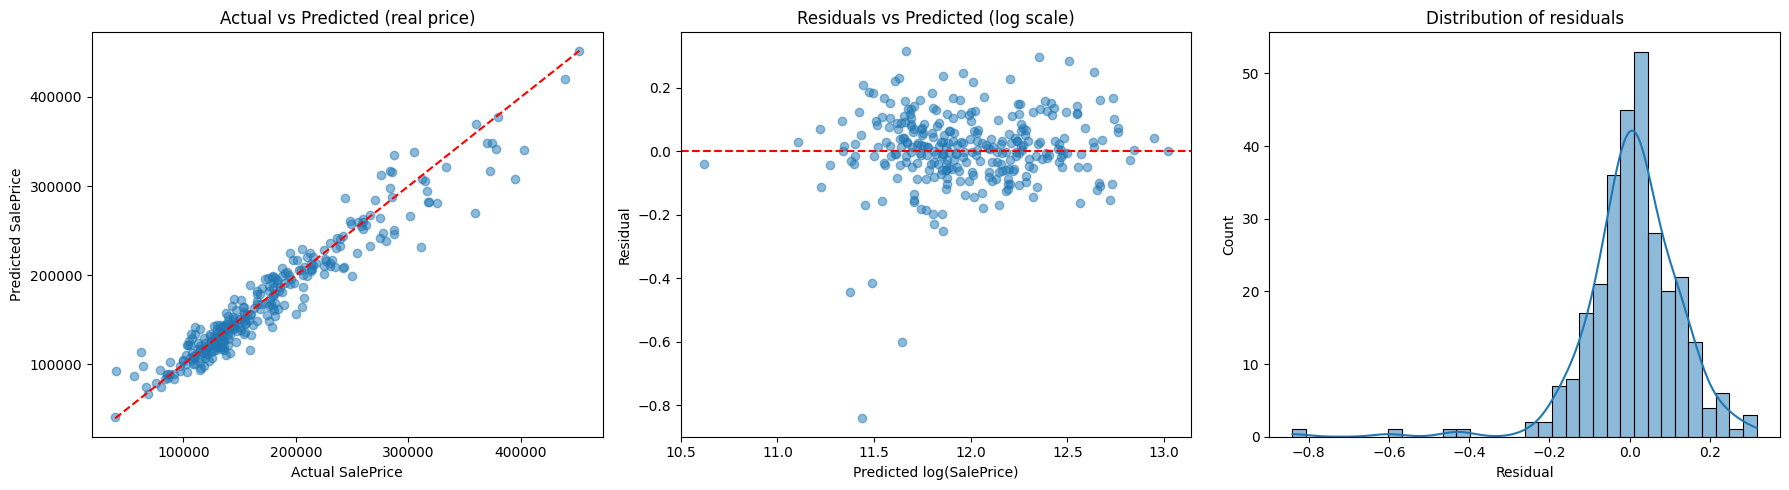

In [57]:
residuals = y_test - pred_log          # log scale
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_real, pred_real, alpha=0.5)
lim = [y_real.min(), y_real.max()]
axes[0].plot(lim, lim, 'r--')
axes[0].set_title('Actual vs Predicted (real price)')
axes[0].set_xlabel('Actual SalePrice'); axes[0].set_ylabel('Predicted SalePrice')

axes[1].scatter(pred_log, residuals, alpha=0.5)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Residuals vs Predicted (log scale)')
axes[1].set_xlabel('Predicted log(SalePrice)'); axes[1].set_ylabel('Residual')

sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set_title('Distribution of residuals')
axes[2].set_xlabel('Residual')
plt.tight_layout()
plt.show()

In [58]:
errors_pct = np.abs(pred_real - y_real) / y_real * 100
print("=== Automatic interpretation of the results ===")
print(f"- Selected model: {best_name}.")
print(f"- R2 = {results.loc['R2', 'Real price ($)']:.3f} on the real price (and {results.loc['R2', 'log(SalePrice)']:.3f} on the log scale): "
      f"the model explains {results.loc['R2', 'Real price ($)']:.0%} of the variation of the sale price.")
print(f"- Typical error: MAE = ${results.loc['MAE', 'Real price ($)']:,.0f}; median error = {np.median(errors_pct):.1f}% of the real price; "
      f"RMSE = ${results.loc['RMSE', 'Real price ($)']:,.0f} (bigger because expensive houses count more).")
print(f"- {np.mean(errors_pct < 10):.0%} of the houses are predicted within 10% of the real price.")
print(f"- Mean residual (log) = {residuals.mean():.3f} (close to 0 means no systematic over/under prediction).")
print(f"- The top 3 models differ by only {tuning_df['After tuning (best_score_)'].max() - tuning_df['After tuning (best_score_)'].min():.3f} in CV R2.")

=== Automatic interpretation of the results ===
- Selected model: Ridge.
- R2 = 0.927 on the real price (and 0.909 on the log scale): the model explains 93% of the variation of the sale price.
- Typical error: MAE = $13,685; median error = 5.9% of the real price; RMSE = $19,609 (bigger because expensive houses count more).
- 69% of the houses are predicted within 10% of the real price.
- Mean residual (log) = 0.009 (close to 0 means no systematic over/under prediction).
- The top 3 models differ by only 0.014 in CV R2.


**Interpretation**
- **R² (real price)** tells how much of the price variation is explained; **MAE** is the average error in dollars; **RMSE / MSE** punish the big errors of expensive houses more.
- **Actual vs Predicted:** points near the red diagonal are good predictions; expensive houses are harder because there are few of them.
- **Residuals vs Predicted:** a random cloud around 0 is what we want; a curve or funnel would show a missing pattern or errors that grow with the price.
- **Histogram of residuals:** bell-shaped and centred on 0 means balanced errors.
- **Limits:** the data is one city (Ames, Iowa, 2006-2010), the neighborhood is target-encoded, and the 2 huge houses removed as outliers are not predicted by this model.

## 12. Conclusions
- Missing values were handled without data leakage (`NA` = no feature, medians from the train data only); target encoding and scaling use train data only.
- Training on `log(SalePrice)` and `log1p` of the skewed features make the models work well on this skewed data.
- The final model was chosen with cross-validation, tuned with `GridSearchCV`, and evaluated on the test set once.
- Possible improvements: feature engineering (total area, age of the house), more tuning, stacking of the best models.

## 13. PCA (extra) and Gradio app

In [59]:
from sklearn.decomposition import PCA
pc=PCA(n_components=10,random_state=42)
X_train_PCA=pc.fit_transform(X_train)
X_test_PCA=pc.transform(X_test)

In [60]:
X_train_PCA.shape

(1164, 10)

In [61]:
import gradio as gr

raw_X = df_clean.drop(columns="SalePrice")
median_idx = (df_clean["SalePrice"] - df_clean["SalePrice"].median()).abs().idxmin()
typical_house = raw_X.loc[[median_idx]]


def prepare_row(row):

    row = row.copy()
    row["LotFrontage"] = row["LotFrontage"].fillna(lot_frontage_median)
    for col in quality_cols:
        row[col] = row[col].map(quality)
    row["CentralAir"] = row["CentralAir"].map({"N": 0, "Y": 1})
    row["MSSubClass"] = row["MSSubClass"].astype(str)

    for col in high_card:
        row[col] = row[col].map(target_means[col]).fillna(y_train.mean())

    # من غير drop_first (الصف واحد فكان هيمسح الأعمدة النصية)، و reindex بيرتب الأعمدة
    row = pd.get_dummies(row, columns=onehot_cols)
    row = row.reindex(columns=X.columns, fill_value=0).astype(float)

    row[skewed] = np.log1p(row[skewed])
    row[num_cols] = scaler.transform(row[num_cols])
    return row


def predict_price(overall_qual, gr_liv_area, total_bsmt_sf, garage_cars, year_built,
                  lot_area, full_bath, neighborhood, kitchen_qual, exter_qual):
    numbers = [overall_qual, gr_liv_area, total_bsmt_sf, year_built, lot_area]
    if any(v is None for v in numbers):
        return " "

    row = typical_house.copy()
    row["OverallQual"] = int(overall_qual)
    row["GrLivArea"] = gr_liv_area
    row["TotalBsmtSF"] = total_bsmt_sf
    row["GarageCars"] = int(garage_cars)
    row["YearBuilt"] = year_built
    row["LotArea"] = lot_area
    row["FullBath"] = int(full_bath)
    row["Neighborhood"] = neighborhood
    row["KitchenQual"] = kitchen_qual
    row["ExterQual"] = exter_qual

    price = np.expm1(best_model.predict(prepare_row(row)))[0]
    return f"Estimated Price: ${price:,.0f}"


demo = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Slider(1, 10, step=1, value=6, label="Overall Quality (1-10)"),
        gr.Number(label="Living Area (sq ft)", value=1500),
        gr.Number(label="Total Basement (sq ft)", value=1000),
        gr.Dropdown(["0", "1", "2", "3", "4"], label="Garage Cars", value="2"),
        gr.Number(label="Year Built", value=1990, precision=0),
        gr.Number(label="Lot Area (sq ft)", value=9000),
        gr.Dropdown(["0", "1", "2", "3"], label="Full Bathrooms", value="2"),
        gr.Dropdown(sorted(df_clean["Neighborhood"].unique()), label="Neighborhood", value="NAmes"),
        gr.Dropdown(["Ex", "Gd", "TA", "Fa"], label="Kitchen Quality", value="TA"),
        gr.Dropdown(["Ex", "Gd", "TA", "Fa"], label="Exterior Quality", value="TA"),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="House Price Prediction App",
    description="Enter the main house details to estimate its sale price. Other details are set to a typical house.",
)

demo.launch(share=True)   # share=True gives a public link when you run it in Colab

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://408390bff684dcddf5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
